### rc_test4_silo

Fixed mistakes in ESN implementation of 'rc_test3_silo' and applied edited ESN to SILO Data. First attempt of a freerun prediction. 

- Queensland Government, & Australian Bureau of Metreorology. (1996). SILO - Australian climate data from 1889 to yesterday [Data set]. In Using spatial interpolation to construct a comprehensive archive of Australian climate data. https://doi.org/10.1016/S1364-8152(01)00008-1  

-- Incorporated growing degree day spacing to make analysis and plotting more comparable
-- Editing slicing of matrices in ESN class  
-- Free-run predictions also attempted: They are when a trained reservoir computer feeds its own input back in   as the next input, instead of receiving real data  
-- Developed updated plots for use in Mid-Year Presentation    

--- Date:   May 2026

In [44]:
import urllib.request
import urllib.parse
import pandas as pd
import io
import numpy as np
import matplotlib.pyplot as plt
from great_tables import GT
import seaborn as sns
from matplotlib.colors import LogNorm  

In [45]:
def collect_data(form,lat,lon,start,finish,username,password='apirequest'):
    """
    quering and requesting data from SILO using API
    """
    params = {'format': form,
              'lat': lat,
              'lon': lon,
              'start': start,
              'finish': finish,
              'username': username,
              'password': password
             }

    api_url = 'https://www.longpaddock.qld.gov.au/cgi-bin/silo' 
    url = api_url + '/DataDrillDataset.php?' + urllib.parse.urlencode(params)
    
    with urllib.request.urlopen(url) as remote:
        data = remote.read()
        body_str = data.decode('utf-8')
        
    return pd.read_csv(io.StringIO(body_str), skiprows=31, sep=r'\s+')


In [46]:
def clean_data(df):
    """
    converting requested dataset into usable pandas dataset
    - extracting dates in format dd/mm/yyyy
    - converting columns to numeric
    - computing cumulative growing degree days using tmin, tmax and tbase (10)
    """
    df = df.drop(index=0).reset_index(drop=True)
    df['Date2'] = pd.to_datetime(df['Date2'], format='%d/%m/%Y')

    # convert columns to numeric 
    for cols in df.columns:
        if cols != 'Date2':
            try:
                df[cols] = pd.to_numeric(df[cols])
            except (ValueError, TypeError):
                pass

    # extract year, month, day
    df['Year'] = df['Date2'].dt.year
    df['Month'] = df['Date2'].dt.month
    df['Day'] = df['Date2'].dt.day
    # apply GDD calculation
    df['T.Avg'] = (df['T.Max'] + df['T.Min']) / 2
    df['GDD'] = np.where(df['T.Avg'] >= 10, df['T.Avg'] - 10, 0)
    # find cumulative growing degree days
    df['GDD.C'] = df['GDD'].cumsum()
    
    return df

def prepare_data(df, by):
    """
    preparing rainfall and cumulative growing degree set variables 
    - perform smoothing on rainfall observations through rolling window average
    -
    - normalise rainfall observations
    - extract normalised rain and gddc vectors
    """

    clean = clean_data(df)
    # smooth rain values using rolling window average
    clean['Rain.Mean'] = clean.Rain.rolling(window=180,min_periods=1).mean()

    # if wanting to retain normal time based spacing (extracts a weekly point)
    if by == "Time":
        clean_rain = clean[['Rain.Mean']].values[::7]
        clean_gddc = clean[['GDD.C']].values[::7]
    else:
        # generate regular gdd poitns every 100 units
        clean_gddc = np.arange(0, clean.GDD.sum(), 100)
        # estimate rainfall at each of these gdd points
        clean_rain = np.interp(clean_gddc, clean["GDD.C"], clean["Rain.Mean"])

    normalised_rain = []
    min_val = min(clean_rain)
    max_val = max(clean_rain)
    diff = max_val - min_val # normalise through min-max scaling
    for x in clean_rain:
        normalised_rain.append((x - min_val) / diff)
    return np.array(normalised_rain).reshape(len(clean_gddc),1), clean_gddc.reshape(len(clean_gddc),1)


In [47]:
#Testing Rain against GDDc for Merreddin 

start_date = '19710101'
end_date = '20260327'

# Merredin (10092)
# collect data with time based spacing
merre_t_data = collect_data('standard','-31.48','118.28',start_date,end_date,'email@gmail.com')
merre_t_rain, merre_tgddc = prepare_data(merre_t_data, by = "Time")

#collect data with gdd spacing
merre_data = collect_data('standard','-31.48','118.28',start_date,end_date,'email@gmail.com')
merre_rain, merre_gddc = prepare_data(merre_data, by = "")

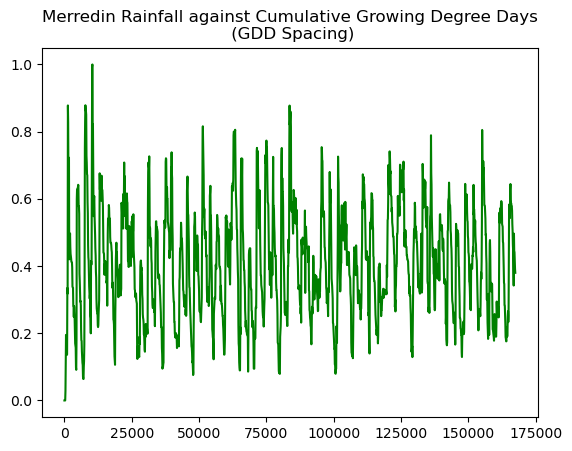

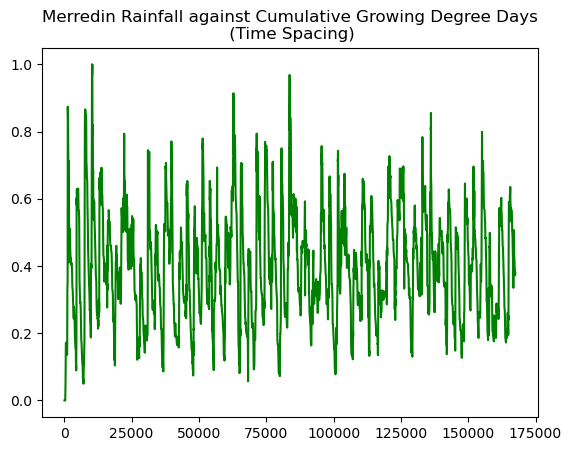

gdd spacing: [100. 100. 100. 100. 100. 100. 100. 100. 100.]
time spacing: [ 89.05  92.25 126.1  112.35 128.8   84.45  90.4  100.85 111.3 ]


In [48]:
# seeing whether there any any visual changes to plotting 
plt.plot(merre_gddc, merre_rain, color="green")
plt.title("Merredin Rainfall against Cumulative Growing Degree Days\n (GDD Spacing)")
plt.show() 


plt.plot(merre_tgddc, merre_t_rain, color="green")
plt.title("Merredin Rainfall against Cumulative Growing Degree Days\n (Time Spacing)")
plt.show() 

# seeing changes in array
print("gdd spacing:", np.diff(merre_gddc[:10].flatten()))
print("time spacing:", np.diff(merre_tgddc[:10].flatten()))

In [ ]:
class ESN:
    """
    N: number of nodes 
    d: average number of connections per node
    rho: spectral radius
    split: proportion of data to take as training  
    """
    def __init__(self, N, d, rho, input_scaling):
        self.N = N
        self.d = d
        self.rho = rho
        self.a = input_scaling


        # random, sparse, reservoir weights:
        ## connections between nodes decided by probability of d/N
        # sampling from normal distribution provides random weight values.
        Weights = np.multiply(
            np.random.binomial(size=(self.N,self.N), p=self.d/self.N, n=1),
            np.random.normal(size=(self.N,self.N)))
        
        # rescale so that rho = largest absolutel eigenvalue (maintaining echo state property)
        self.Vadj = Weights * (self.rho/np.max(np.absolute(np.linalg.eig(Weights)[0])))

        # input matrix: maps the scalar input to every node of the reservoir
        self.Vin = self.a * np.random.uniform(-1,1,size=(1, self.N))

        # bias matrix: bias added to each node's activation
        self.Vbias = np.random.uniform(-1,1,size=(1,self.N))

    def run_reservoir(self,input_data):
        """
        drive the reservoir using the input_data and return the state at every timestep
        states = (len(input_data), N)
        - comments keep track of matrix multiplications
        """
        states = np.zeros((len(input_data)+1, self.N)) # (timesteps x N)
        for i in range(1, len(input_data)+1): # start at 1 to access previous reservoir state
            states[i, :] = np.tanh(
                np.dot(states[i-1:i, :], self.Vadj) + # (1,N) x (N,N) = (1,N)
                np.dot(input_data[i-1:i], self.Vin) +  # (1,1) x (1,N) = (1,N)
                self.Vbias)
        return states[1:,:] # (timesteps x N), skip first row as it stays zero due to no input being processed.
      

    def train(self, train_input, train_target, washout, beta=0.01):
        """
        fit the output weights
        - remove the initial washout period from the states and target 
        - compute Vout through ridge regression
        """
        train_states = self.run_reservoir(train_input)
        # removing the washout period 
        train_states = train_states[washout:,:] 
        train_target = train_target[washout:,:]

        # using ridge regression to compute the output weights through training
        self.Vout = np.dot(
            np.linalg.pinv(np.dot(train_states.T,train_states) + beta*np.identity(self.N)), #(N,t) x (t,N) = (N,N) + (N,N)
                           np.dot(train_states.T, train_target)) #(N,t) x (t,1) = (N,1)
                           #Vout = (N,1)
                           

    def freerun(self, test_input, steps):
        """
        first attempt at a freerun prediction
        - train the reservoir computer on some testing input data 
        - following training, the readout prediction replaces the input data  
        """
        readout = self.run_reservoir(test_input) 
        freerun_states = np.zeros((steps, self.N))
        freerun_states[0,:] = readout[-1,:]
        for i in range(1, steps):
            freerun_states[i, :] = np.tanh(np.dot(freerun_states[i-1:i, :],self.Vadj) + #(1,N) x (N,N) = (1,N)
                                           np.dot(np.dot(freerun_states[i-1:i], self.Vout), self.Vin) + 
                                           self.Vbias) # the prediction replaces input_data[i-1:i]
                                           

        return np.dot(freerun_states, self.Vout)
                     

    def predict(self, test_input, test_target,washout=10):
        """
        run reservoir on test data and map states to predictions
        - remove initial washout period from states and testing input
        - compute Root Mean Squared Error of predictions 
        """
        test_states = self.run_reservoir(test_input)

        # apply trained linear readout
        predictions = np.dot(test_states, self.Vout)

        # compute RMSE of predictions
        rmse = np.sqrt(((predictions[washout:] - test_input[washout:])**2).mean())

        return predictions, rmse
    


In [50]:
def splitting_data(rain,gddc,step):
    """
    function to split rainfall and cumulative growing degree days by step size
    80% of data for training, 20% for testing
    """
    # step to decide how far prediction goes
    train_size = int(len(rain) * 0.8)
    train_input = rain[:train_size-step]
    train_target = rain[step:train_size]

    test_input = rain[train_size:-step]
    test_input_x = gddc[train_size:-step]
    test_target = rain[train_size+step:]
    test_target_x = gddc[train_size+step:]

    return train_input, train_target, test_input, test_input_x, test_target, test_target_x

def plotting_data(x_values, test_actual, test_predictions, title):
    """
    function to plot the resulting predictions against the actual data
    """
    plt.plot(x_values,test_actual, label = 'actual_values',color='blue',)
    plt.plot(x_values, test_predictions, label='predicted',color='green',alpha=0.6)
    plt.xlabel('Cumulative Growing Degree Days (°C Days)')
    plt.ylabel('Standardised Rain (mm)')
    plt.title(title)
    plt.legend(['Actual Values', 'Prediction'])
    plt.show()

def rc_for_location(esn, rain, gddc, step):
    """
    function run the ESN prediction and return RMSE 
    """
    train_input, train_target, test_target, x_vals = splitting_data(rain, gddc, step)
    esn.train(train_input, train_target, washout=100)
    rain_pred, rmse = esn.predict(test_target)

    return rmse

def rc_for_location_withplot(esn, rain, gddc, step):
    """
    function to generate predictions for a particular given location and step size and produce plot
    """
    train_input, train_target, test_input, test_input_x, test_target, test_target_x = splitting_data(rain, gddc, step)
    esn.train(train_input, train_target, washout=100)
    rain_pred, rmse = esn.predict(test_input, test_target)
    plt.plot(test_target_x[10:], test_target[10:],label = 'actual_values',color='blue',)
    plt.plot(test_target_x[10:], rain_pred[10:], label='predicted',color='green',alpha=0.6)
    plt.xlabel('Cumulative Growing Degree Days (°C Days)')
    plt.ylabel('Standardised Rain (mm)')
    plt.legend(['Actual Values', 'Prediction'])
    plt.show()

def rc_with_freerun(esn, rain, gddc, step):
   """
   function to generate freerun predictions for a particular given location and step size and produce plot
   """
   train_input, train_target, test_input, test_input_x, test_target, test_target_x = splitting_data(rain, gddc, step)
   esn.train(train_input, train_target, washout=100)
   free_run_test = esn.freerun(train_target, step)
   plt.plot(test_target[:100], label = 'actual_values',color='blue',)
   plt.plot(free_run_test, label='predicted',color='green',alpha=0.6)
   plt.xlabel('Cumulative Growing Degree Days (°C Days)')
   plt.ylabel('Standardised Rain (mm)')
   plt.legend(['Actual Values', 'Freerun Prediction'])
   plt.show()

## Free-run Test

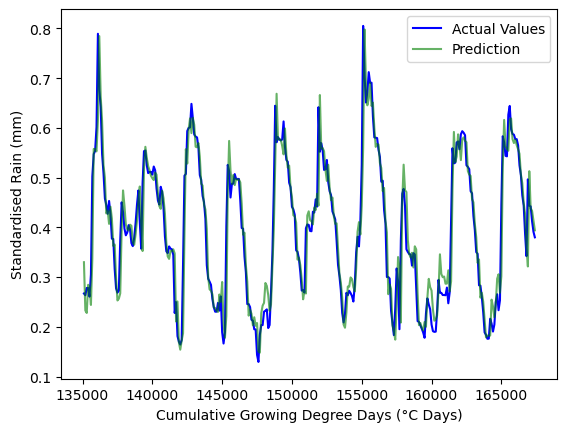

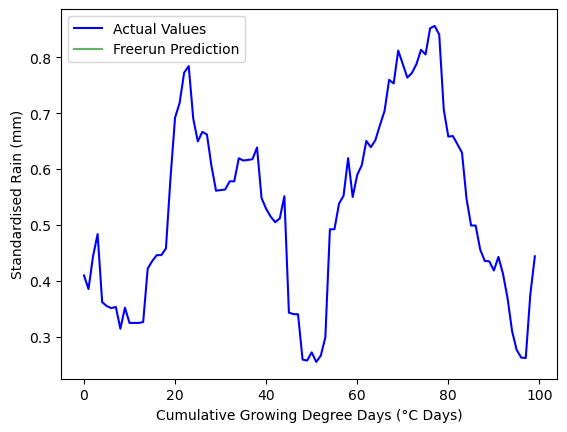

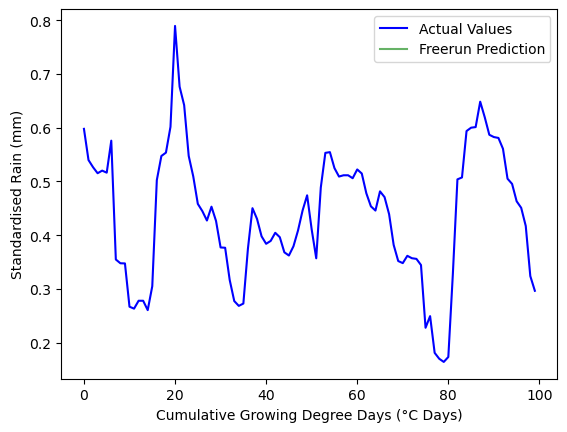

In [51]:
np.random.seed(123)

esn = ESN(300,10,1.0,1.0)
merre_esn_time = rc_for_location_withplot(esn, merre_rain, merre_gddc, step=1)


# PROBLEM: Freerun predictions are not plotting, error likely inside of freerun method itself. 
merre_freerun_time = rc_with_freerun(esn, merre_t_rain, merre_tgddc, step=1)
merre_freerun = rc_with_freerun(esn, merre_rain, merre_gddc, step=1)